In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


In [2]:
from google.colab import files
uploaded = files.upload()

Saving sales_data.csv to sales_data (1).csv


In [3]:
df = pd.read_excel("sales_data.csv", sheet_name="Sheet1", engine="openpyxl")
df.head()

,Order_ID,Date,Customer,City,Product,Category,Quantity,Unit_Price,Total_Sales,Total Revenue
0,104,2026-10-04,Arun,Bengaluru,UPI_Device,Hardware,4,5000,20000,98000.0
1,106,2026-10-06,Kiran,Hyderabad,POS_Machine,Hardware,2,8000,16000,NaN
2,109,2026-10-09,Anu,Mumbai,UPI_Device,Hardware,3,5000,15000,NaN
3,101,2026-10-01,Ravi,Bengaluru,UPI_Device,Hardware,2,5000,10000,NaN
4,103,2026-10-03,Priya,Chennai,POS_Machine,Hardware,1,8000,8000,NaN


In [4]:
print(df.shape)
df.info()
print(df.isnull().sum())

(10, 10)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10 entries, 0 to 9
Data columns (total 10 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   Order_ID       10 non-null     int64         
 1   Date           10 non-null     datetime64[ns]
 2   Customer       10 non-null     object        
 3   City           10 non-null     object        
 4   Product        10 non-null     object        
 5   Category       10 non-null     object        
 6   Quantity       10 non-null     int64         
 7   Unit_Price     10 non-null     int64         
 8   Total_Sales    10 non-null     int64         
 9   Total Revenue  1 non-null      float64       
dtypes: datetime64[ns](1), float64(1), int64(4), object(4)
memory usage: 932.0+ bytes
Order_ID         0
Date             0
Customer         0
City             0
Product          0
Category         0
Quantity         0
Unit_Price       0
Total_Sales      0
Total Revenue    9
d

In [5]:
# stray column teesey (Excel lo table bayata unna cell)
df = df.drop(columns=["Total Revenue"], errors="ignore")

# duplicates
print("Duplicates:", df.duplicated().sum())
df = df.drop_duplicates()

# date ni datetime ki marchu
df["Date"] = pd.to_datetime(df["Date"])

# Total_Sales = Quantity * Unit_Price check
print((df["Quantity"] * df["Unit_Price"] == df["Total_Sales"]).all())

df.head()

Duplicates: 0
True


,Order_ID,Date,Customer,City,Product,Category,Quantity,Unit_Price,Total_Sales
0,104,2026-10-04,Arun,Bengaluru,UPI_Device,Hardware,4,5000,20000
1,106,2026-10-06,Kiran,Hyderabad,POS_Machine,Hardware,2,8000,16000
2,109,2026-10-09,Anu,Mumbai,UPI_Device,Hardware,3,5000,15000
3,101,2026-10-01,Ravi,Bengaluru,UPI_Device,Hardware,2,5000,10000
4,103,2026-10-03,Priya,Chennai,POS_Machine,Hardware,1,8000,8000


In [6]:
total_revenue = df["Total_Sales"].sum()
total_orders = df["Order_ID"].nunique()
avg_order_value = df["Total_Sales"].mean()
total_quantity = df["Quantity"].sum()

print("Total Revenue:", total_revenue)
print("Total Orders:", total_orders)
print("Average Order Value:", round(avg_order_value, 2))
print("Total Quantity:", total_quantity)

product_sales = df.groupby("Product")["Total_Sales"].sum().sort_values(ascending=False)
city_sales = df.groupby("City")["Total_Sales"].sum().sort_values(ascending=False)
category_sales = df.groupby("Category")["Total_Sales"].sum()

print(product_sales)
print(city_sales)
print(category_sales)

Total Revenue: 98000
Total Orders: 10
Average Order Value: 9800.0
Total Quantity: 32
Product
UPI_Device     45000
POS_Machine    24000
Credit_Card    18000
Debit_Card     11000
Name: Total_Sales, dtype: int64
City
Bengaluru    36000
Hyderabad    26000
Mumbai       20000
Chennai      16000
Name: Total_Sales, dtype: int64
Category
Finance     29000
Hardware    69000
Name: Total_Sales, dtype: int64


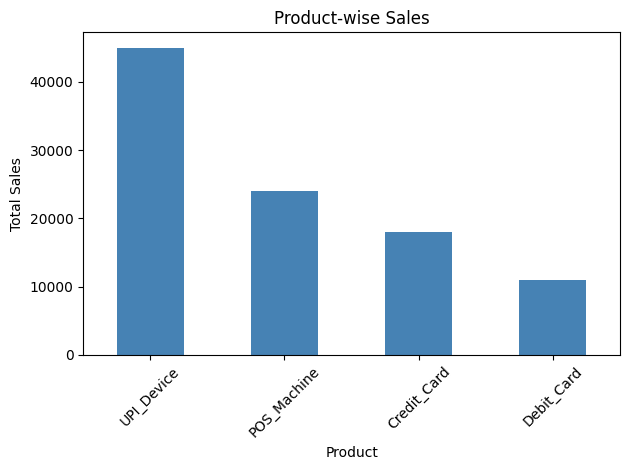

In [7]:
product_sales.plot(kind="bar", color="steelblue")
plt.title("Product-wise Sales")
plt.xlabel("Product")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

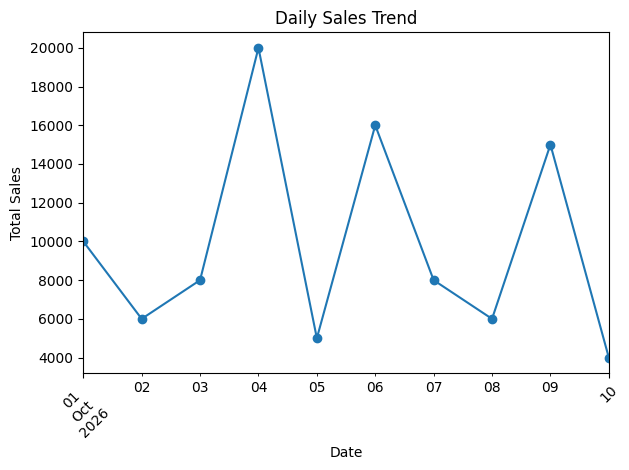

In [8]:
daily_sales = df.groupby("Date")["Total_Sales"].sum()
daily_sales.plot(kind="line", marker="o")
plt.title("Daily Sales Trend")
plt.xlabel("Date")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

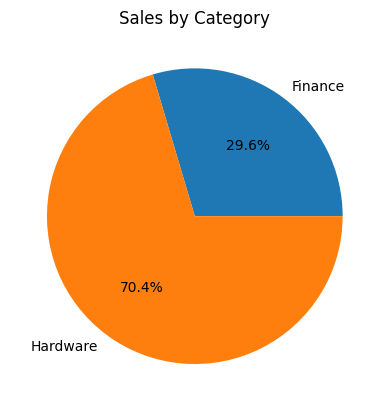

In [9]:
category_sales.plot(kind="pie", autopct="%1.1f%%")
plt.title("Sales by Category")
plt.ylabel("")
plt.show()

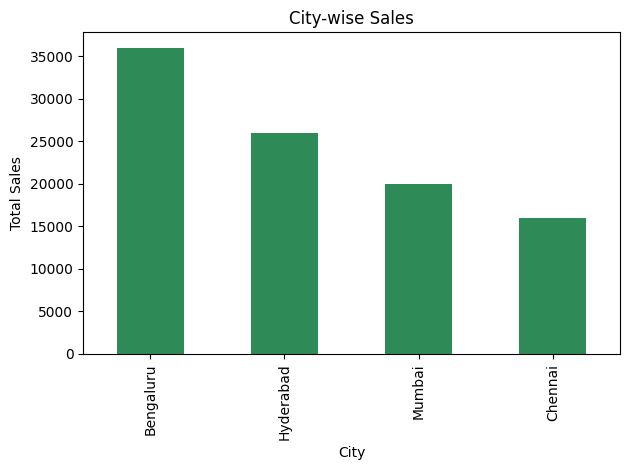

In [10]:
city_sales.plot(kind="bar", color="seagreen")
plt.title("City-wise Sales")
plt.xlabel("City")
plt.ylabel("Total Sales")
plt.tight_layout()
plt.show()

In [11]:
df.to_csv("cleaned_sales_data.csv", index=False)
files.download("cleaned_sales_data.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [12]:
company = "Bluestock"

prices = [500, 1500, 12000]
for p in prices:
    print(p)

product = {"name": "Laptop", "price": 50000}
print(product["name"])

def add_gst(price):
    return price * 1.18

print(add_gst(1000))

# file handling
with open("kpi_summary.txt", "w") as f:
    f.write("Total Revenue: " + str(total_revenue))

with open("kpi_summary.txt", "r") as f:
    print(f.read())

500
1500
12000
Laptop
1180.0
Total Revenue: 98000
